In [36]:
import numpy as np
import pandas as pd

In [37]:
train_df = pd.read_csv("train.csv")

In [38]:
test_df = pd.read_csv("test.csv")
print(test_df)

        ID ApplicationDate  Age  AnnualIncome  CreditScore  LoanAmount  \
0        0      1979-01-03   49        207095          850       14458   
1        1      2006-04-10   28         64653          674       65491   
2        2      2013-11-28   41        300000          768       16811   
3        3      1995-08-24   50        300000          850       48737   
4        4      1980-06-15   35        300000          672       51916   
...    ...             ...  ...           ...          ...         ...   
4995  4995      1993-03-19   40        300000          850       12696   
4996  4996      2015-09-27   39         75014          572       49380   
4997  4997      1993-10-04   43         15000          454       32810   
4998  4998      1981-05-10   53         98467          850       28446   
4999  4999      1998-11-27   49         15000          300      395083   

      LoanDuration MaritalStatus  NumberOfDependents HomeOwnershipStatus  ...  \
0               60        Sing

In [39]:
q1 = train_df["RiskScore"].quantile(0.25)
q3 = train_df["RiskScore"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df_filtered = train_df[(train_df["RiskScore"] >= lower_bound) & (train_df["RiskScore"] <= upper_bound)]

y_train_df = df_filtered["RiskScore"]
train_df = df_filtered.drop(columns=["RiskScore"])

print(train_df)

      ApplicationDate   Age  AnnualIncome  CreditScore  LoanAmount  \
0          2010-06-26  27.0       66829.0        549.0     17290.0   
1          1996-09-23  55.0      172147.0        850.0     16110.0   
2          2015-01-19  51.0      300000.0        850.0     38436.0   
3          1981-05-12  25.0       34683.0        847.0     19186.0   
4          1995-05-07  55.0      300000.0        850.0     30437.0   
...               ...   ...           ...          ...         ...   
11011      1980-01-15  39.0      300000.0        850.0      7721.0   
11012      2010-07-10  57.0      300000.0        850.0     14756.0   
11013      2003-10-22  28.0       15000.0        300.0     51361.0   
11014      1983-05-12  23.0       15000.0        302.0     30724.0   
11016      2000-01-07  41.0      300000.0          NaN         NaN   

       LoanDuration MaritalStatus  NumberOfDependents HomeOwnershipStatus  \
0              60.0      Divorced                 1.0                Rent   
1    

анализируем графики

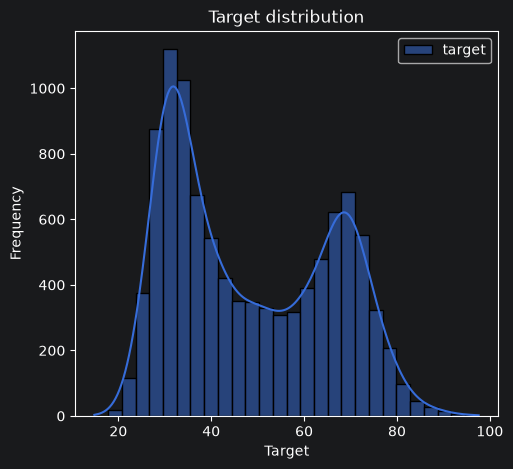

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=y_train_df, kde=True, label='target')

plt.title('Target distribution')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.legend()

plt.show()

анализ величин

In [41]:
train_df["IncomePerDependent"] = train_df["AnnualIncome"] / (train_df["NumberOfDependents"] + 1).replace(0, np.nan)

train_df["DebtBurden"] = train_df["MonthlyDebtPayments"] / train_df["MonthlyIncome"].replace(0, np.nan)

train_df["MonthlyIncomePerDebt"] = train_df["MonthlyIncome"] / (train_df["MonthlyDebtPayments"] + 1).replace(0, np.nan)

train_df["LoanToAnnualIncome"] = train_df["LoanAmount"] / train_df["AnnualIncome"].replace(0, np.nan)

train_df["LoanToMonthlyIncome"] = train_df["LoanAmount"] / train_df["MonthlyIncome"].replace(0, np.nan)

train_df["LoanPaymentToIncome"] = train_df["MonthlyLoanPayment"] / train_df["MonthlyIncome"].replace(0, np.nan)

train_df["TotalPaymentBurden"] = (train_df["MonthlyDebtPayments"] + train_df["MonthlyLoanPayment"]) / train_df[
    "MonthlyIncome"].replace(0, np.nan)

# 2. Активы и капитал
train_df["AssetsToIncome"] = train_df["TotalAssets"] / train_df["AnnualIncome"].replace(0, np.nan)

train_df["LiabilitiesToAssets"] = train_df["TotalLiabilities"] / train_df["TotalAssets"].replace(0, np.nan)

train_df["NetWorthToIncome"] = train_df["NetWorth"] / train_df["AnnualIncome"].replace(0, np.nan)

train_df["SavingsToIncome"] = train_df["SavingsAccountBalance"] / train_df["AnnualIncome"].replace(0, np.nan)

train_df["CheckingToIncome"] = train_df["CheckingAccountBalance"] / train_df["AnnualIncome"].replace(0, np.nan)

train_df["SavingsToDebt"] = train_df["SavingsAccountBalance"] / (train_df["MonthlyDebtPayments"] * 12).replace(0,
                                                                                                               np.nan)

train_df["LiquidAssets"] = train_df["SavingsAccountBalance"] + train_df["CheckingAccountBalance"]

train_df["LiquidAssetsToDebt"] = train_df["LiquidAssets"] / train_df["TotalLiabilities"].replace(0, np.nan)

train_df["CreditHistoryPerAge"] = train_df["LengthOfCreditHistory"] / train_df["Age"].replace(0, np.nan)

train_df["ExperiencePerAge"] = train_df["Experience"] / train_df["Age"].replace(0, np.nan)

train_df["JobTenurePerExperience"] = train_df["JobTenure"] / train_df["Experience"].replace(0, np.nan)

train_df["CreditLinesPerHistory"] = train_df["NumberOfOpenCreditLines"] / train_df["LengthOfCreditHistory"].replace(0,
                                                                                                                    np.nan)

train_df["InquiriesPerCreditLine"] = train_df["NumberOfCreditInquiries"] / (
        train_df["NumberOfOpenCreditLines"] + 1).replace(0, np.nan)

train_df["InterestRateSpread"] = train_df["InterestRate"] - train_df["BaseInterestRate"]

train_df["InterestRateRelative"] = train_df["InterestRate"] / train_df["BaseInterestRate"].replace(0, np.nan)

train_df["CreditScorePerInquiry"] = train_df["CreditScore"] / (train_df["NumberOfCreditInquiries"] + 1).replace(0,
                                                                                                                np.nan)

train_df["CreditScorePerDebt"] = train_df["CreditScore"] * (1 - train_df["TotalDebtToIncomeRatio"])

# 5. Взаимодействия
train_df["CreditScore_Income"] = train_df["CreditScore"] * train_df["MonthlyIncome"]

train_df["CreditScore_InterestRate"] = train_df["CreditScore"] * train_df["InterestRate"]

train_df["Income_InterestRate"] = train_df["MonthlyIncome"] * train_df["InterestRate"]

train_df["CreditScore_DebtRatio"] = train_df["CreditScore"] * train_df["TotalDebtToIncomeRatio"]

train_df["Assets_Liabilities"] = train_df["TotalAssets"] * train_df["TotalLiabilities"]

train_df["PaymentHistory_Utilization"] = train_df["PaymentHistory"] * train_df["CreditCardUtilizationRate"]

train_df["CreditScore_LoanAmount"] = train_df["CreditScore"] * train_df["LoanAmount"]

train_df["Income_LoanDuration"] = train_df["MonthlyIncome"] * train_df["LoanDuration"]

train_df["Experience_Income"] = train_df["Experience"] * train_df["MonthlyIncome"]

for col in [
    "CreditScore",
    "AnnualIncome",
    "MonthlyIncome",
    "LoanAmount",
    "TotalAssets",
    "NetWorth",
    "MonthlyLoanPayment",
]:
    train_df[f"{col}_squared"] = train_df[col] ** 2

In [42]:
test_df["IncomePerDependent"] = test_df["AnnualIncome"] / (test_df["NumberOfDependents"] + 1).replace(0, np.nan)

test_df["DebtBurden"] = test_df["MonthlyDebtPayments"] / test_df["MonthlyIncome"].replace(0, np.nan)

test_df["MonthlyIncomePerDebt"] = test_df["MonthlyIncome"] / (test_df["MonthlyDebtPayments"] + 1).replace(0, np.nan)

test_df["LoanToAnnualIncome"] = test_df["LoanAmount"] / test_df["AnnualIncome"].replace(0, np.nan)

test_df["LoanToMonthlyIncome"] = test_df["LoanAmount"] / test_df["MonthlyIncome"].replace(0, np.nan)

test_df["LoanPaymentToIncome"] = test_df["MonthlyLoanPayment"] / test_df["MonthlyIncome"].replace(0, np.nan)

test_df["TotalPaymentBurden"] = (test_df["MonthlyDebtPayments"] + test_df["MonthlyLoanPayment"]) / test_df[
    "MonthlyIncome"].replace(0, np.nan)

# 2. Активы и капитал
test_df["AssetsToIncome"] = test_df["TotalAssets"] / test_df["AnnualIncome"].replace(0, np.nan)

test_df["LiabilitiesToAssets"] = test_df["TotalLiabilities"] / test_df["TotalAssets"].replace(0, np.nan)

test_df["NetWorthToIncome"] = test_df["NetWorth"] / test_df["AnnualIncome"].replace(0, np.nan)

test_df["SavingsToIncome"] = test_df["SavingsAccountBalance"] / test_df["AnnualIncome"].replace(0, np.nan)

test_df["CheckingToIncome"] = test_df["CheckingAccountBalance"] / test_df["AnnualIncome"].replace(0, np.nan)

test_df["SavingsToDebt"] = test_df["SavingsAccountBalance"] / (test_df["MonthlyDebtPayments"] * 12).replace(0, np.nan)

test_df["LiquidAssets"] = test_df["SavingsAccountBalance"] + test_df["CheckingAccountBalance"]

test_df["LiquidAssetsToDebt"] = test_df["LiquidAssets"] / test_df["TotalLiabilities"].replace(0, np.nan)

test_df["CreditHistoryPerAge"] = test_df["LengthOfCreditHistory"] / test_df["Age"].replace(0, np.nan)

test_df["ExperiencePerAge"] = test_df["Experience"] / test_df["Age"].replace(0, np.nan)

test_df["JobTenurePerExperience"] = test_df["JobTenure"] / test_df["Experience"].replace(0, np.nan)

test_df["CreditLinesPerHistory"] = test_df["NumberOfOpenCreditLines"] / test_df["LengthOfCreditHistory"].replace(0,
                                                                                                                 np.nan)

test_df["InquiriesPerCreditLine"] = test_df["NumberOfCreditInquiries"] / (
        test_df["NumberOfOpenCreditLines"] + 1).replace(0, np.nan)

test_df["InterestRateSpread"] = test_df["InterestRate"] - test_df["BaseInterestRate"]

test_df["InterestRateRelative"] = test_df["InterestRate"] / test_df["BaseInterestRate"].replace(0, np.nan)

test_df["CreditScorePerInquiry"] = test_df["CreditScore"] / (test_df["NumberOfCreditInquiries"] + 1).replace(0, np.nan)

test_df["CreditScorePerDebt"] = test_df["CreditScore"] * (1 - test_df["TotalDebtToIncomeRatio"])

# 5. Взаимодействия
test_df["CreditScore_Income"] = test_df["CreditScore"] * test_df["MonthlyIncome"]

test_df["CreditScore_InterestRate"] = test_df["CreditScore"] * test_df["InterestRate"]

test_df["Income_InterestRate"] = test_df["MonthlyIncome"] * test_df["InterestRate"]

test_df["CreditScore_DebtRatio"] = test_df["CreditScore"] * test_df["TotalDebtToIncomeRatio"]

test_df["Assets_Liabilities"] = test_df["TotalAssets"] * test_df["TotalLiabilities"]

test_df["PaymentHistory_Utilization"] = test_df["PaymentHistory"] * test_df["CreditCardUtilizationRate"]

test_df["CreditScore_LoanAmount"] = test_df["CreditScore"] * test_df["LoanAmount"]

test_df["Income_LoanDuration"] = test_df["MonthlyIncome"] * test_df["LoanDuration"]

test_df["Experience_Income"] = test_df["Experience"] * test_df["MonthlyIncome"]

for col in [
    "CreditScore",
    "AnnualIncome",
    "MonthlyIncome",
    "LoanAmount",
    "TotalAssets",
    "NetWorth",
    "MonthlyLoanPayment",
]:
    test_df[f"{col}_squared"] = test_df[col] ** 2

In [43]:
for column in train_df.columns:
    s = train_df[column]
    if s.dtype != np.float64 and s.dtype != np.int32:
        continue
    print(f"{column}: skew={s.skew()}, mean={s.mean()}, median={s.median()}")

Age: skew=0.17014606399447182, mean=39.86234423676012, median=40.0
AnnualIncome: skew=0.6694131950640246, mean=131532.94548286605, median=88994.5
CreditScore: skew=-0.7037406634371203, mean=677.9115152753653, median=722.0
LoanAmount: skew=3.495512165585967, mean=29925.122509451314, median=21836.0
LoanDuration: skew=0.6893136012409421, mean=53.425233644859816, median=48.0
NumberOfDependents: skew=0.714787635691098, mean=1.5678543613707165, median=1.0
MonthlyDebtPayments: skew=3.4883658603921437, mean=546.4379278634924, median=398.0
CreditCardUtilizationRate: skew=0.5877608948869075, mean=0.28456480443616805, median=0.26231278016028636
NumberOfOpenCreditLines: skew=0.5786270836368047, mean=3.0291082554517135, median=3.0
NumberOfCreditInquiries: skew=0.9733601865603754, mean=0.9779984423676013, median=1.0
DebtToIncomeRatio: skew=0.7042780458093854, mean=0.2502719116286192, median=0.22830877050464632
BankruptcyHistory: skew=4.0080358144667185, mean=0.052620823541432514, median=0.0
Previous

In [44]:
skewed_features = [
    "LoanAmount",
    "MonthlyDebtPayments",
    "SavingsAccountBalance",
    "CheckingAccountBalance",
    "TotalAssets",
    "TotalLiabilities",
    "NetWorth",
    "MonthlyLoanPayment",

    "TotalDebtToIncomeRatio",
    "IncomePerDependent",
    "DebtBurden",
    "MonthlyIncomePerDebt",
    "LoanToAnnualIncome",
    "LoanToMonthlyIncome",
    "LoanPaymentToIncome",
    "TotalPaymentBurden",
    "AssetsToIncome",
    "LiabilitiesToAssets",
    "NetWorthToIncome",
    "SavingsToIncome",
    "CheckingToIncome",
    "SavingsToDebt",
    "LiquidAssets",
    "LiquidAssetsToDebt",
    "JobTenurePerExperience",
    "CreditLinesPerHistory",
    "InquiriesPerCreditLine",
    "CreditScore_DebtRatio",
    "Assets_Liabilities",
    "CreditScore_LoanAmount",
    "AnnualIncome_squared",
    "LoanAmount_squared",
    "TotalAssets_squared",
    "NetWorth_squared",
    "MonthlyLoanPayment_squared",
]

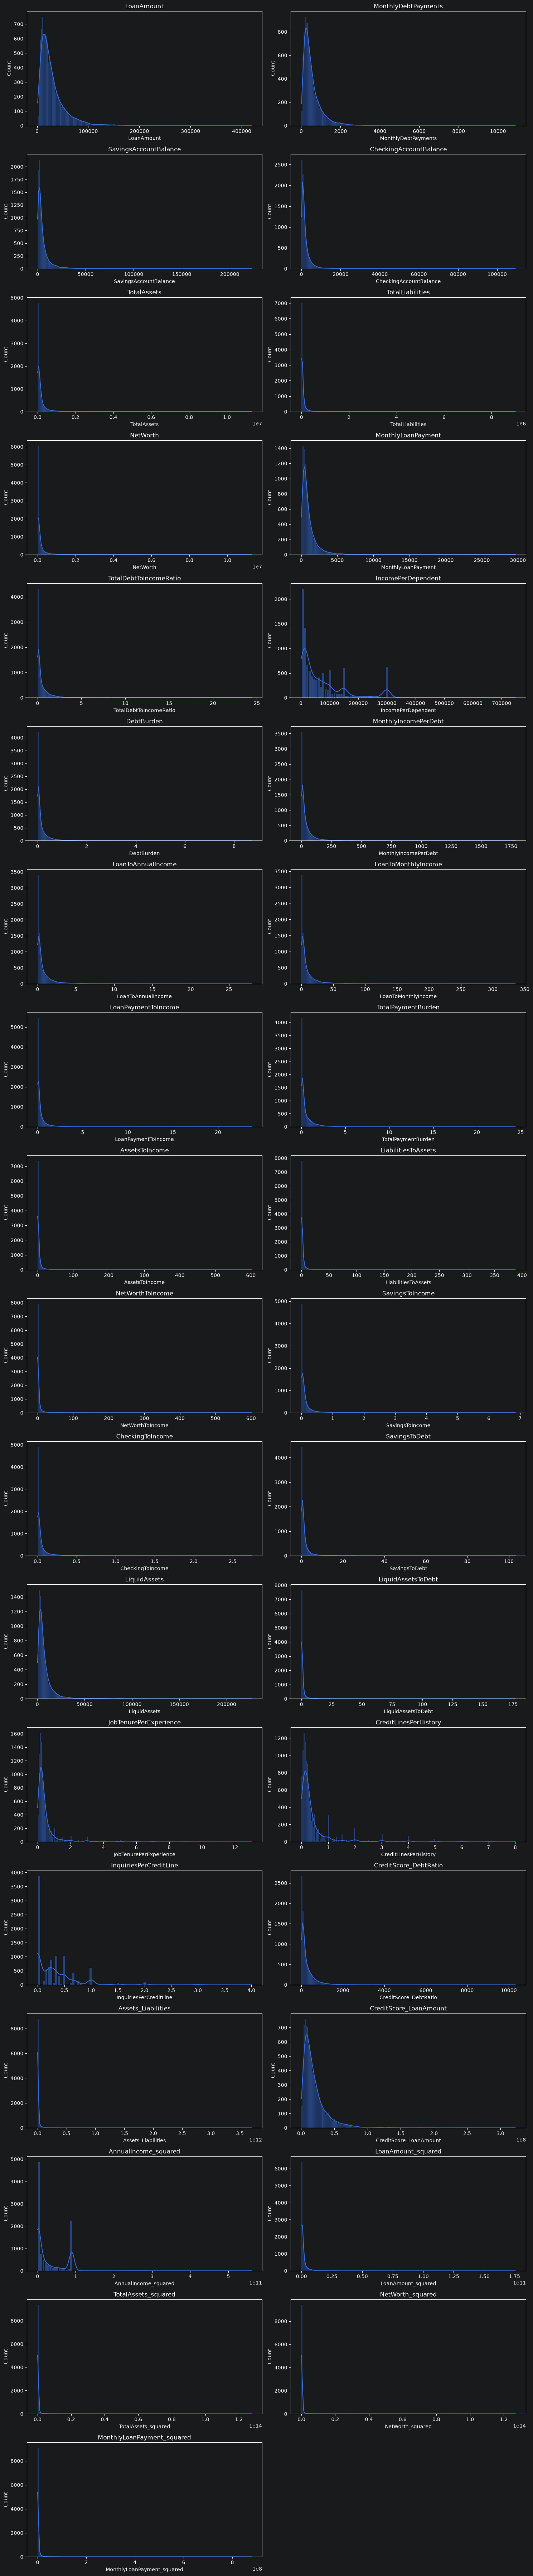

In [45]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

n = len(skewed_features)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, skewed_features):
    sns.histplot(data=train_df, x=col, kde=True, ax=ax)
    ax.set_title(col)

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

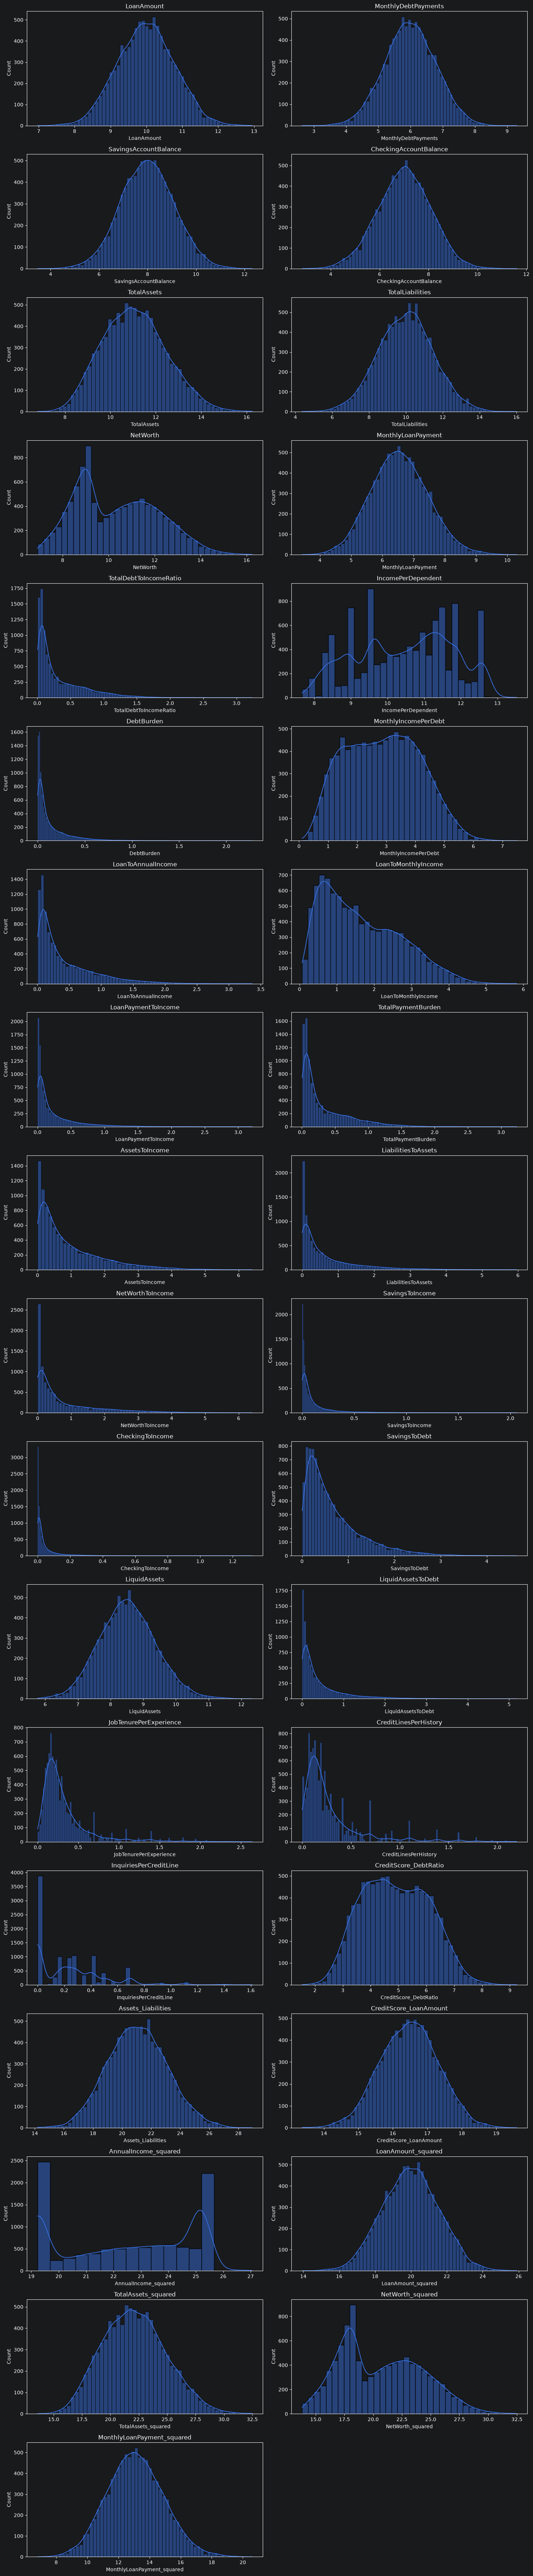

In [46]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

n = len(skewed_features)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, skewed_features):
    log_train_df = train_df.copy()
    log_train_df[col] = np.log1p(log_train_df[col])
    sns.histplot(data=log_train_df, x=col, kde=True, ax=ax)
    ax.set_title(col)

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [47]:
train_df["ApplicationDate"] = pd.to_datetime(train_df["ApplicationDate"])

month_degree = (2 * np.pi * (12 - train_df["ApplicationDate"].dt.month)) / 12
train_df["ApplicationMonthSin"] = round(np.sin(month_degree), 2)
train_df["ApplicationMonthCos"] = round(np.cos(month_degree), 2)

train_df["ApplicationDay"] = train_df["ApplicationDate"].dt.day
train_df["ApplicationYear"] = train_df["ApplicationDate"].dt.year

train_df = train_df.drop(columns=["ApplicationDate"])

print(train_df["ApplicationMonthSin"])
print(train_df["ApplicationMonthCos"])
print(train_df["ApplicationDay"])
print(train_df["ApplicationYear"])

0        0.00
1        1.00
2       -0.50
3       -0.50
4       -0.50
         ... 
11011   -0.50
11012    0.50
11013    0.87
11014   -0.50
11016   -0.50
Name: ApplicationMonthSin, Length: 10272, dtype: float64
0       -1.00
1        0.00
2        0.87
3       -0.87
4       -0.87
         ... 
11011    0.87
11012   -0.87
11013    0.50
11014   -0.87
11016    0.87
Name: ApplicationMonthCos, Length: 10272, dtype: float64
0        26
1        23
2        19
3        12
4         7
         ..
11011    15
11012    10
11013    22
11014    12
11016     7
Name: ApplicationDay, Length: 10272, dtype: int32
0        2010
1        1996
2        2015
3        1981
4        1995
         ... 
11011    1980
11012    2010
11013    2003
11014    1983
11016    2000
Name: ApplicationYear, Length: 10272, dtype: int32


In [48]:
test_df["ApplicationDate"] = pd.to_datetime(test_df["ApplicationDate"])

month_degree = (2 * np.pi * (12 - test_df["ApplicationDate"].dt.month)) / 12
test_df["ApplicationMonthSin"] = round(np.sin(month_degree), 2)
test_df["ApplicationMonthCos"] = round(np.cos(month_degree), 2)

test_df["ApplicationDay"] = test_df["ApplicationDate"].dt.day
test_df["ApplicationYear"] = test_df["ApplicationDate"].dt.year

test_df = test_df.drop(columns=["ApplicationDate"])

добавляем новые признаки

In [49]:
categorical_features = train_df.select_dtypes(str).columns
print(categorical_features)

Index(['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose',
       'EmploymentStatus', 'EducationLevel'],
      dtype='str')


In [50]:
key_features = [
    "MonthlyIncome",
    "CreditScore",
    "InterestRate",
    "BaseInterestRate",
    "TotalDebtToIncomeRatio",
    "NetWorth",

    "DebtToIncomeRatio",
    "LengthOfCreditHistory",
]

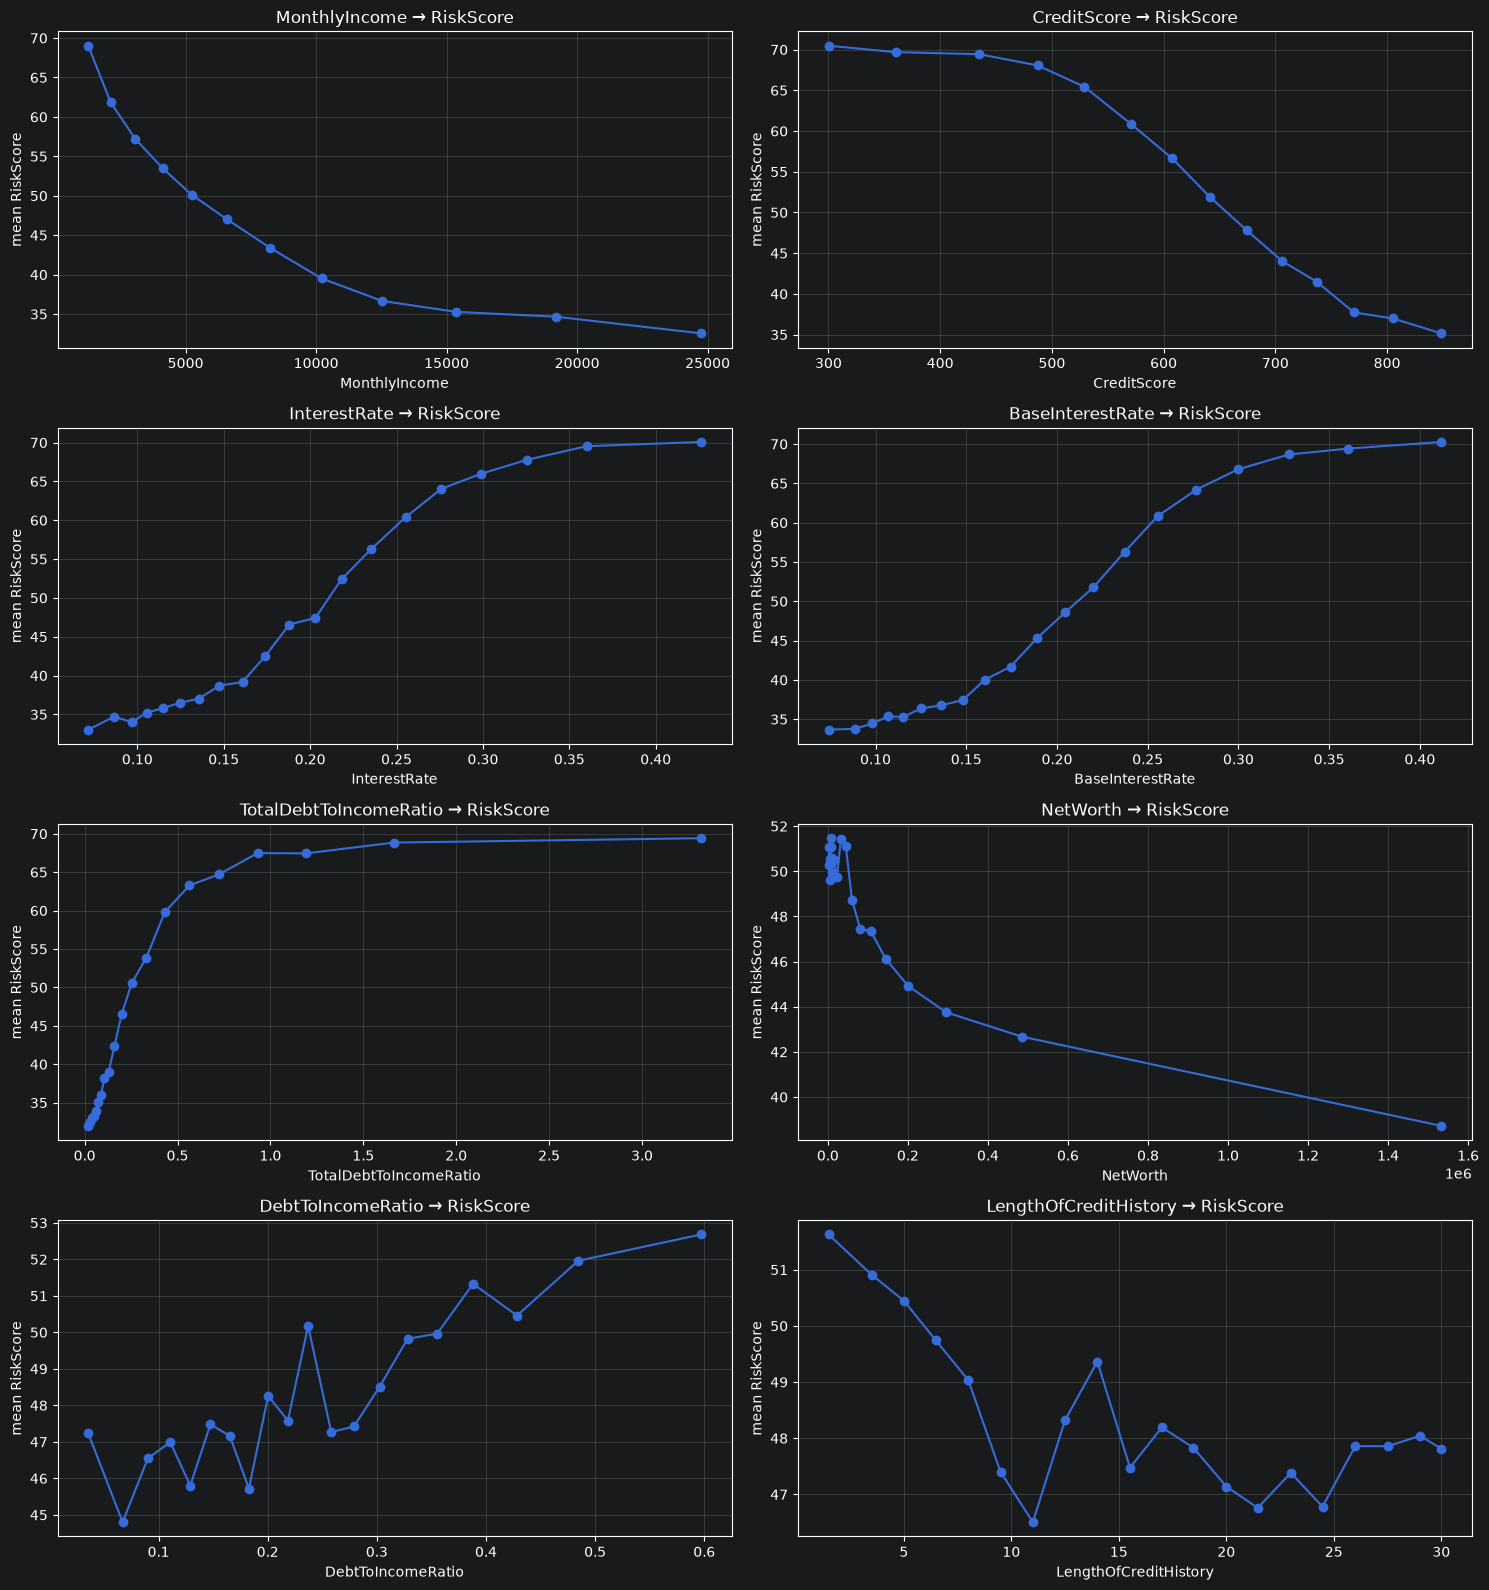

In [51]:
import math
import numpy as np
import matplotlib.pyplot as plt

TARGET = "RiskScore"
N_BINS = 20

n = len(key_features)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, key_features):
    d = df_filtered[[col, TARGET]].dropna().copy()
    d['bin'] = pd.qcut(d[col], q=N_BINS, duplicates='drop')
    agg = d.groupby('bin', observed=True).agg(
        x=(col, 'mean'),
        y=(TARGET, 'mean'),
        n=(TARGET, 'size'),
    )

    ax.plot(agg['x'], agg['y'], marker='o', lw=1.5)
    ax.set_xlabel(col)
    ax.set_ylabel(f'mean {TARGET}')
    ax.set_title(f'{col} → {TARGET}')
    ax.grid(alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [52]:
interaction_features = [
    "MonthlyIncome",
    "CreditScore",
    "InterestRate",
    "TotalDebtToIncomeRatio",

    "BaseInterestRate",
    "NetWorth",
    "DebtToIncomeRatio",
    "LengthOfCreditHistory",
]

In [53]:
numerical_features = train_df.select_dtypes(np.number).columns

numerical_features = numerical_features.drop(
    ["ApplicationMonthSin", "ApplicationMonthCos", "ApplicationDay", "ApplicationYear", *skewed_features, *key_features, *interaction_features])

print(numerical_features)

Index(['Age', 'AnnualIncome', 'LoanDuration', 'NumberOfDependents',
       'CreditCardUtilizationRate', 'NumberOfOpenCreditLines',
       'NumberOfCreditInquiries', 'BankruptcyHistory', 'PreviousLoanDefaults',
       'PaymentHistory', 'UtilityBillsPaymentHistory', 'JobTenure',
       'Experience', 'CreditHistoryPerAge', 'ExperiencePerAge',
       'InterestRateSpread', 'InterestRateRelative', 'CreditScorePerInquiry',
       'CreditScorePerDebt', 'CreditScore_Income', 'CreditScore_InterestRate',
       'Income_InterestRate', 'PaymentHistory_Utilization',
       'Income_LoanDuration', 'Experience_Income', 'CreditScore_squared',
       'MonthlyIncome_squared'],
      dtype='str')


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, SplineTransformer, \
    PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

log_transformer = FunctionTransformer(np.log1p, validate=True)

skewed_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("log", log_transformer),
    ("scaler", StandardScaler()),
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

spline_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("spline", SplineTransformer(n_knots=12, degree=3, knots="quantile", extrapolation="constant")),
    ("scaler", StandardScaler()),
])

interaction_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler2", StandardScaler()),
])

ct = ColumnTransformer([
    ("ohe", OneHotEncoder(), categorical_features),
    ("log", skewed_pipeline, skewed_features),
    ("numerical", numerical_pipeline, numerical_features),
    ("spline", spline_pipeline, key_features),
    ("interaction", interaction_pipeline, interaction_features),
])

In [55]:
x_train = ct.fit_transform(train_df)
x_test = ct.transform(test_df)

Кросс-валидация

In [56]:
from sklearn.model_selection import KFold
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error as mse

kf = KFold(n_splits=5)

errors = []
models = []

for train_index, test_index in kf.split(x_train):
    X_train_fold, X_test_fold = x_train[train_index], x_train[test_index]
    y_train_fold, y_test_fold = y_train_df.to_numpy()[train_index], y_train_df.to_numpy()[test_index]

    model = ElasticNet(l1_ratio=0.90, alpha=0.0147, max_iter=3_000)
    model.fit(X_train_fold, y_train_fold)
    models.append(model)
    errors.append(mse(y_test_fold, model.predict(X_test_fold)))
errors


C:\Users\rvova\PycharmProjects\mai_labs_machine_learning\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.046204e+02, tolerance: 2.430e+02
  model = cd_fast.enet_coordinate_descent(
C:\Users\rvova\PycharmProjects\mai_labs_machine_learning\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.237149e+02, tolerance: 2.438e+02
  model = cd_fast.enet_coordinate_descent(


[24.10979959070963,
 24.983176467403744,
 24.5117325589942,
 25.17793256234081,
 25.30463209920811]

In [57]:
from sklearn.linear_model import ElasticNetCV

model = ElasticNetCV(
    l1_ratio=[.1, .5, .7, .9, .95, .99, 1],
    cv=5,
    max_iter=3_000,
)
model.fit(x_train, y_train_df)

print(f"Лучший l1_ratio: {model.l1_ratio_}")
print(f"Лучший alpha: {model.alpha_}")

Лучший l1_ratio: 1.0
Лучший alpha: 0.01794658516727612
